# AML-GraphMiner — quick start

This notebook walks through the whole toolkit in a few minutes **on synthetic data**
(an IBM-AML-like generator ships with the package, so nothing has to be downloaded):

1. generate / load transactions into the canonical schema,
2. split them **in time** (train < validation < test) like a real deployment would,
3. detect classical laundering motifs (fan-in / fan-out, smurfing, cycles, scatter-gather,
   gather-scatter) and measure what they recover,
4. train a tabular detector on leak-free features,
5. explain an alert in a way an investigator can audit,
6. save the detector and score new transactions with it,
7. find risk communities (rings of relay accounts),
8. detect unusual transactions **without labels** with a graph auto-encoder,
9. do all of this in the web investigation interface.

> The numbers below come from a **synthetic** dataset and say nothing about real-world
> performance; reproducible benchmarks on the IBM AML data are in `02_ibm_aml_benchmark`.

In [1]:
%pip install -q "aml-graphminer[viz]"

In [2]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import aml_graphminer as aml

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
print("aml-graphminer", aml.__version__)

aml-graphminer 0.1.0


## 1. Data

`generate_transactions` produces a table with the same logical columns as the IBM AML files
(`Timestamp, From Bank, Account, To Bank, Account, Amount Received, ...`) and injects
laundering motifs together with look-alike *legitimate* behaviour (payroll bursts, merchant
bursts, unrelated triangles) so that detectors are not trivially perfect.

With real data you would call `aml.read_transactions("HI-Small_Trans.csv")` instead — the
result has the same canonical schema.

In [3]:
df = aml.generate_transactions(
    n_accounts=900, n_background=7000, days=10, illicit_ratio=0.02, seed=7
)
print(
    f"{len(df):,} transactions, {df['sender'].nunique() + df['receiver'].nunique():,} account slots"
)
print("injected motifs:", df.attrs["injected"])
df.head()

7,167 transactions, 1,853 account slots
injected motifs: {'fan_out': 3, 'fan_in': 3, 'cycle': 3, 'scatter_gather': 3, 'gather_scatter': 2, 'smurfing': 2}


,timestamp,sender,receiver,amount,currency,transaction_type,amount_received,currency_received,sender_bank,receiver_bank,label,pattern,source_row,attempt_id
tx_id,,,,,,,,,,,,,,
0,2022-09-01 00:02:00,5_000021B7,3_00000877,518.84,US Dollar,Credit Card,518.84,US Dollar,5,3,0.0,,4249,-1
1,2022-09-01 00:05:00,3_00002C42,7_00002C59,94.82,Yuan,Credit Card,11.59,Swiss Franc,3,7,0.0,,3071,-1
2,2022-09-01 00:05:00,8_00001A9F,12_00003721,1981.73,US Dollar,Credit Card,1981.73,US Dollar,8,12,0.0,,6666,-1
3,2022-09-01 00:06:00,12_000003F2,6_00001CC7,2337.96,US Dollar,ACH,2337.96,US Dollar,12,6,0.0,,1676,-1
4,2022-09-01 00:16:00,11_000012EC,1_00002614,1246.68,Euro,Cash,1355.09,US Dollar,11,1,0.0,,3870,-1


In [4]:
print("laundering share: {:.2%}".format(df["label"].mean()))
df.groupby("pattern").size().sort_values(ascending=False)

laundering share: 1.84%


pattern
                  7035
scatter_gather      36
fan_out             24
gather_scatter      22
fan_in              20
smurfing            19
cycle               11
dtype: int64

## 2. Temporal split

Random splits leak the future into the past in transaction data. `temporal_split` cuts the
time-ordered table 60 / 20 / 20 — exactly the protocol of the original Colab notebooks.

In [5]:
masks = aml.temporal_split(df)
pd.DataFrame(
    {
        "transactions": {k: int(v.sum()) for k, v in masks.items()},
        "laundering": {k: int(df.loc[v, "label"].sum()) for k, v in masks.items()},
    }
)

,transactions,laundering
train,4300,79
val,1433,19
test,1434,34


## 3. Structural-motif detection

The scanner needs no training: each detector looks for one well-known laundering structure.
Every alert carries **evidence** (which accounts, which transactions, which numbers).

In [6]:
scanner = aml.PatternScanner()
result = scanner.scan(df)
print(result.summary())
result.to_frame().head(8)[["pattern", "score", "n_tx", "n_accounts", "total_amount"]]

{'n_alerts': 138, 'alerts_by_pattern': {'fan_in': 57, 'fan_out': 44, 'smurfing': 20, 'cycle': 4, 'scatter_gather': 2, 'gather_scatter': 10, 'community': 1}, 'n_flagged_transactions': 865, 'n_transactions': 7167, 'timings_seconds': {'fan_in': 0.014, 'fan_out': 0.012, 'smurfing': 0.04, 'cycle': 0.13, 'scatter_gather': 0.02, 'gather_scatter': 0.015, 'community': 0.051}}


,pattern,score,n_tx,n_accounts,total_amount
0,cycle,0.940168,3,3,32049.05
1,gather_scatter,0.934763,28,26,16780.39
2,cycle,0.913208,4,4,14072.35
3,cycle,0.909796,4,4,216752.99
4,smurfing,0.883628,22,22,18457.48
5,smurfing,0.882129,16,16,27336.14
6,scatter_gather,0.830449,12,8,38378.60
7,gather_scatter,0.829252,13,14,5262.58


How much of the injected laundering does each detector recover, and how precise are its
alerts? (`recall_same` counts only the *matching* motif, `recall_any` any alert.)

In [7]:
from aml_graphminer.detectors.patterns.evaluation import (
    alert_precision_table,
    evaluate_scan,
    pattern_recall_table,
)

print({k: round(v, 3) for k, v in evaluate_scan(df, result).items() if isinstance(v, float)})
pattern_recall_table(df, result).round(3)

{'threshold': 0.0, 'n': 7167.0, 'n_pos': 132.0, 'pr_auc': 0.273, 'roc_auc': 0.933, 'f1': 0.243, 'precision': 0.14, 'recall': 0.917, 'recall_at_k': 0.235, 'recall_at_100': 0.182, 'recall_at_1000': 0.917, 'recall_at_0.1pct': 0.023, 'recall_at_1pct': 0.091}


,pattern,n_tx,recall_any,recall_same
0,cycle,11,1.000,1.000
1,fan_in,20,1.000,1.000
2,fan_out,24,1.000,1.000
3,gather_scatter,22,0.864,0.500
4,scatter_gather,36,0.778,0.556
5,smurfing,19,1.000,1.000


In [8]:
alert_precision_table(df, result).round(3)

,pattern,n_alerts,n_tx_covered,tx_precision,alert_precision
0,community,1,12,1.000,1.000
1,cycle,4,14,0.786,0.750
2,fan_in,57,342,0.102,0.088
3,fan_out,44,299,0.221,0.182
4,gather_scatter,10,107,0.103,0.100
5,scatter_gather,2,20,1.000,1.000
6,smurfing,20,195,0.154,0.200


## 4. Leak-free features and a tabular detector

`FeaturePipeline` is fitted **on the training transactions only** and then applied to the
other splits. Edge features use trailing windows (1 h, 24 h, 7 d, all-time), so a
transaction never sees the future; node features are rates computed on the graph that was
observable at each split.

In [9]:
pipeline = aml.FeaturePipeline().fit(df, masks["train"])
features = pipeline.transform_splits(df, masks)
print(
    "edge features:", features["train"].edge.shape, "| node features:", features["train"].node.shape
)
features["train"].edge_cols[:12]

edge features: (7167, 47) | node features: (981, 13)


['log_paid', 'log_recv', 'same_cur', 'same_bank', 'h_sin', 'h_cos', 'fmt_ACH', 'fmt_Bitcoin', 'fmt_Cash', 'fmt_Cheque', 'fmt_Credit Card', 'fmt_Reinvestment']

In [10]:
from aml_graphminer.detectors.bundle import TabularDetector

detector = TabularDetector.fit(df, "hgb", seed=0)
detector.describe()

{'model_type': 'tabular', 'kind': 'hgb', 'threshold': 0.9287697906229213, 'n_features': 73, 'metrics': {'threshold': 0.9287697906229213, 'n': 1434.0, 'n_pos': 34.0, 'pr_auc': 0.8140430945568735, 'roc_auc': 0.9925840336134454, 'f1': 0.4186046511627907, 'precision': 1.0, 'recall': 0.2647058823529412, 'recall_at_k': 0.7352941176470589, 'recall_at_100': 1.0, 'recall_at_1000': 1.0, 'recall_at_0.1pct': 0.029411764705882353, 'recall_at_1pct': 0.38235294117647056}}

`metrics` are computed on the **test** split with the threshold chosen on **validation**.
On a ~2 % positive-rate dataset prefer PR-AUC / recall@k over accuracy or ROC-AUC.

In [11]:
pd.Series(detector.metrics).round(4)

threshold              0.9288
n                   1434.0000
n_pos                 34.0000
pr_auc                 0.8140
roc_auc                0.9926
f1                     0.4186
precision              1.0000
recall                 0.2647
recall_at_k            0.7353
recall_at_100          1.0000
recall_at_1000         1.0000
recall_at_0.1pct       0.0294
recall_at_1pct         0.3824
dtype: float64

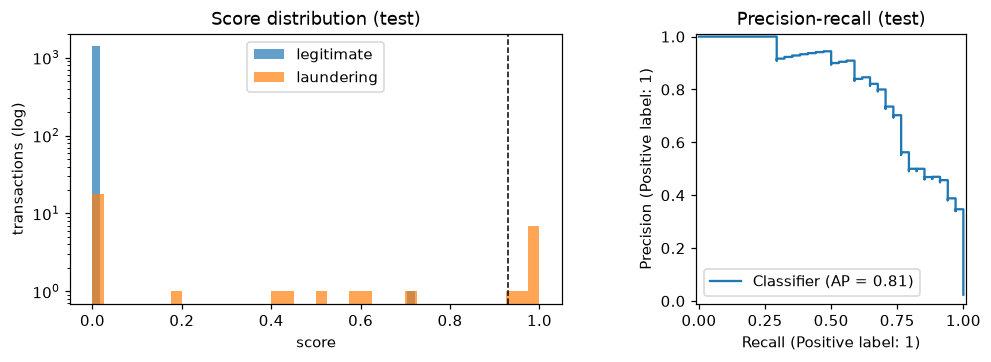

In [12]:
test = df[masks["test"]]
scores = detector.score(test, context=df[~masks["test"]])  # history is context, not scored
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(scores[test["label"] == 0], bins=40, alpha=0.7, label="legitimate", log=True)
ax[0].hist(scores[test["label"] == 1], bins=40, alpha=0.7, label="laundering", log=True)
ax[0].axvline(detector.threshold, color="k", ls="--", lw=1)
ax[0].set(xlabel="score", ylabel="transactions (log)", title="Score distribution (test)")
ax[0].legend()
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(test["label"], scores, ax=ax[1])
ax[1].set_title("Precision-recall (test)")
plt.tight_layout()

## 5. Explanations an investigator can audit

Two complementary tools:

* **Pattern evidence** — exact: the alert that contains the transaction and the numbers
  behind it (no approximation).
* **Occlusion** — model-agnostic: remove each neighbouring transaction and see how the score
  moves. It works with *any* detector (tabular or GNN).

In [13]:
from aml_graphminer.explainers import (
    OcclusionExplainer,
    TransactionIndex,
    detector_score_fn,
    explain_with_patterns,
    plot_explanation,
)

alert = result.alerts[0]
tx_id = int(alert.tx_ids[0])
explanation = explain_with_patterns(df, tx_id, result)
print(explanation.to_markdown())

### Transaction 2011 — patterns
- score: **0.935**
- Part of 2 structural alert(s). gather_scatter: money is collected by a hub then redistributed to other accounts (hub=2_000020E3, n_sources=9, n_targets=16, gathered_amount=17,964.43, scattered_amount=18,342.45, conservation_ratio=1.02). fan_in: many accounts send money to one account in a short time (collection) (hub=2_000020E3, n_counterparties=9, n_transactions=12, span_seconds=84,780.00, window_seconds=86,400.00, amount_cv=1.18).
- pattern `gather_scatter` (alert score 0.93)
- pattern `fan_in` (alert score 0.53)

| tx | sender → receiver | amount | importance |
|---|---|---:|---:|
| 2033 | 2_000020E3 → 8_00001657 | 862.84 | +0.935 |
| 2061 | 6_00002037 → 2_000020E3 | 1,305.04 | +0.935 |
| 2063 | 2_000020E3 → 6_00002907 | 487.78 | +0.935 |
| 2136 | 2_000020E3 → 10_00001C39 | 5,645.70 | +0.935 |
| 2141 | 9_000033F5 → 2_000020E3 | 128.39 | +0.935 |


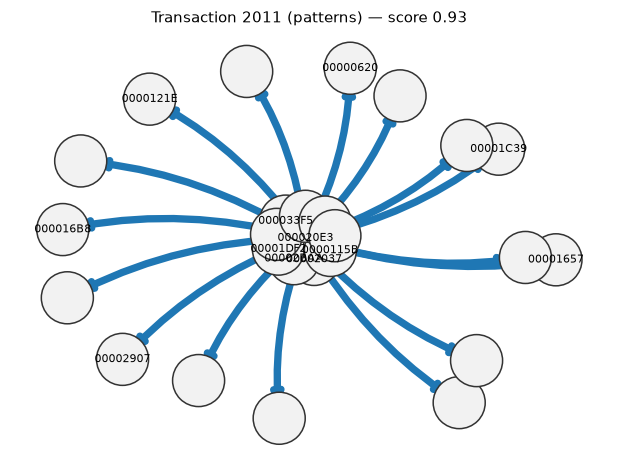

In [14]:
plot_explanation(explanation)
plt.show()

In [15]:
index = TransactionIndex(df)
flagged = scores[scores >= detector.threshold].sort_values(ascending=False)
target = int(flagged.index[0])
occlusion = OcclusionExplainer(
    detector_score_fn(detector), hops=2, max_edges=40, threshold=detector.threshold
).explain(df, target, index)
print(occlusion.to_markdown())

### Transaction 6387 — occlusion
- score: **0.985** (threshold 0.929)
- Score 0.985 computed with 18 neighbouring transactions. The most influential neighbour is transaction 6356 (1_000018CC → 5_00003B3E, 6,657.89): it raises the score by 0.057.

| tx | sender → receiver | amount | importance |
|---|---|---:|---:|
| 6356 | 1_000018CC → 5_00003B3E | 6,657.89 | +0.057 |
| 6375 | 4_00003B6E → 1_00003B12 | 5,909.36 | +0.025 |
| 6406 | 9_00003B46 → 1_00003B12 | 6,243.85 | +0.023 |
| 6410 | 3_00003B29 → 1_00003B12 | 6,121.67 | +0.023 |
| 6367 | 5_00003B7C → 1_00003B12 | 5,960.97 | +0.022 |

| attribute | value | importance |
|---|---|---:|
| amount | 6,588.01 | +0.173 |
| amount_received | 6,588.01 | +0.000 |
| transaction_type | Wire | +0.000 |
| currency | Yuan | +0.000 |
| currency_received | Yuan | +0.000 |


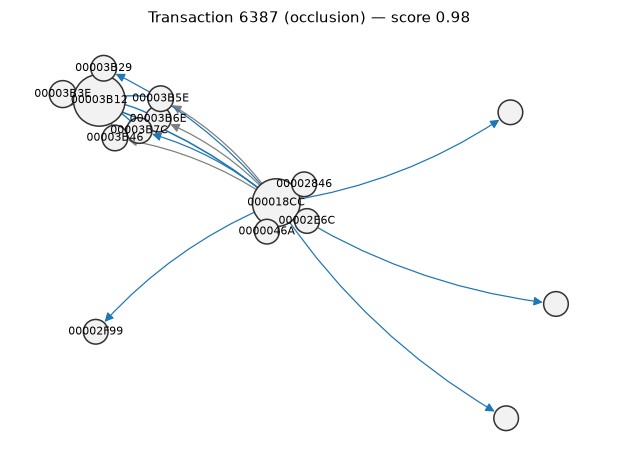

In [16]:
plot_explanation(occlusion)
plt.show()

Every explanation is plain data: `explanation.to_json()`, `explanation.to_networkx()`.

In [17]:
print(occlusion.to_json()[:600], "...")

{
  "tx_id": 6387,
  "method": "occlusion",
  "score": 0.984644,
  "threshold": 0.92877,
  "summary": "Score 0.985 computed with 18 neighbouring transactions. The most influential neighbour is transaction 6356 (1_000018CC → 5_00003B3E, 6,657.89): it raises the score by 0.057.",
  "edges": [
    {
      "tx_id": 6387,
      "sender": "5_00003B3E",
      "receiver": "1_00003B12",
      "amount": 6588.01,
      "timestamp": "2022-09-09 02:11:00",
      "importance": 0.984644,
      "role": "target"
    },
    {
      "tx_id": 6375,
      "sender": "4_00003B6E",
      "receiver": "1_00003B12",
    ...


## 6. Persist and reuse

A saved detector is a directory (`config.json` + weights) that contains the feature
statistics, so scoring new data needs no re-fitting. The same directory can be exported to
the Hugging Face Hub with `amlgm export-hub`.

In [18]:
import tempfile

from aml_graphminer.detectors.bundle import load_detector

with tempfile.TemporaryDirectory() as tmp:
    detector.save(tmp)
    restored = load_detector(tmp)
    same = (restored.score(test, context=df[~masks["test"]]) - scores).abs().max()
print("max |score difference| after reload:", float(same))

max |score difference| after reload: 0.0


## 7. Risk communities

Besides the six motifs, the scanner looks for **risk communities**: small groups organised
around *relay* accounts (accounts that forward most of what they receive) whose money mostly
stays inside the group within a few days — rings of mule accounts. Groups are connected
components of the relay transactions, split with Louvain when they are too large.

In [19]:
communities = [a for a in result.alerts if a.pattern == "community"]
print(f"{len(communities)} risk communities")
if communities:
    strongest = max(communities, key=lambda a: a.score)
    print(strongest.evidence)
pattern_recall_table(df, scanner.scan(df)).round(3)

1 risk communities
{'n_members': 8, 'n_relays': 6, 'n_internal_tx': 12, 'internal_share': 0.8286796542366935, 'mean_flow_through': 0.7334126684063063, 'span_seconds': 21660.0, 'internal_amount': 75670.46, 'has_cycle': False}


,pattern,n_tx,recall_any,recall_same
0,cycle,11,1.000,1.000
1,fan_in,20,1.000,1.000
2,fan_out,24,1.000,1.000
3,gather_scatter,22,0.864,0.500
4,scatter_gather,36,0.778,0.556
5,smurfing,19,1.000,1.000


## 8. Learning without labels: the graph auto-encoder

Confirmed laundering cases are rare and arrive months later. `AutoEncoderDetector` (CLI:
`amlgm train --model gae`) is trained **without any label**: a GNN encodes the accounts and two
decoders try to rebuild every transaction (its features and the link itself). Transactions it
rebuilds badly are unusual; the score is their percentile in the training distribution.
Labels, when present, are only used to choose the alert threshold. Needs the `gnn` extra.

In [20]:
from aml_graphminer.utils import has_module

if has_module("torch") and has_module("torch_geometric"):
    from aml_graphminer.detectors.gnn import AutoEncoderDetector, GNNConfig

    gae = AutoEncoderDetector.fit(
        df, GNNConfig(kind="sage", hidden=32, epochs=3, batch_size=1024), seed=0
    )
    base_rate = df.loc[masks["test"], "label"].mean()
    print(
        f"unsupervised GAE — test PR-AUC {gae.metrics['pr_auc']:.3f} "
        f"(a random ranking scores {base_rate:.3f}), ROC-AUC {gae.metrics['roc_auc']:.3f}"
    )
else:
    print("PyTorch Geometric is not installed here: the auto-encoder is skipped.")

unsupervised GAE — test PR-AUC 0.193 (a random ranking scores 0.024), ROC-AUC 0.932


## 9. The web investigation interface

Everything above is also available in a browser:

```bash
amlgm serve --demo                 # demo detector + synthetic data, http://127.0.0.1:8000/ui/
amlgm serve runs/hgb --data data/Synth-Small_Trans.csv
```

The interface shows the dashboard of a dataset, the motif alerts with their sub-graph, every
transaction with its score and an explanation drawn as a graph, and the profile of any account.
The transaction graph can also be explored in Neo4j: `amlgm export-neo4j <file> <dir>`.

## Next steps

* `02_ibm_aml_benchmark` — EDA and the benchmark (motifs vs. tabular vs. GCN/SAGE/GAT vs. the
  unsupervised auto-encoder) on the IBM AML datasets, with several seeds and confidence intervals.
* `03_explainability` — GNNExplainer, PGExplainer, Captum, attention weights and how to read an
  explanation.
* `amlgm --help` — the same workflow from the command line.